<a href="https://colab.research.google.com/github/Ganesh5016/fundamentals-of-machine-learning/blob/main/FOML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

FIND-S ALGORITHM
Positive: ['Sunny', 'Warm', 'Normal', 'Strong'] -> ['Sunny', 'Warm', 'Normal', 'Strong']
Positive: ['Sunny', 'Warm', 'High', 'Strong'] -> ['Sunny', 'Warm', '?', 'Strong']
Negative: ['Rainy', 'Cold', 'High', 'Strong'] -> ignored
Positive: ['Sunny', 'Warm', 'High', 'Weak'] -> ['Sunny', 'Warm', '?', '?']
Negative: ['Rainy', 'Warm', 'Normal', 'Weak'] -> ignored
FINAL HYPOTHESIS: ['Sunny', 'Warm', '?', '?']


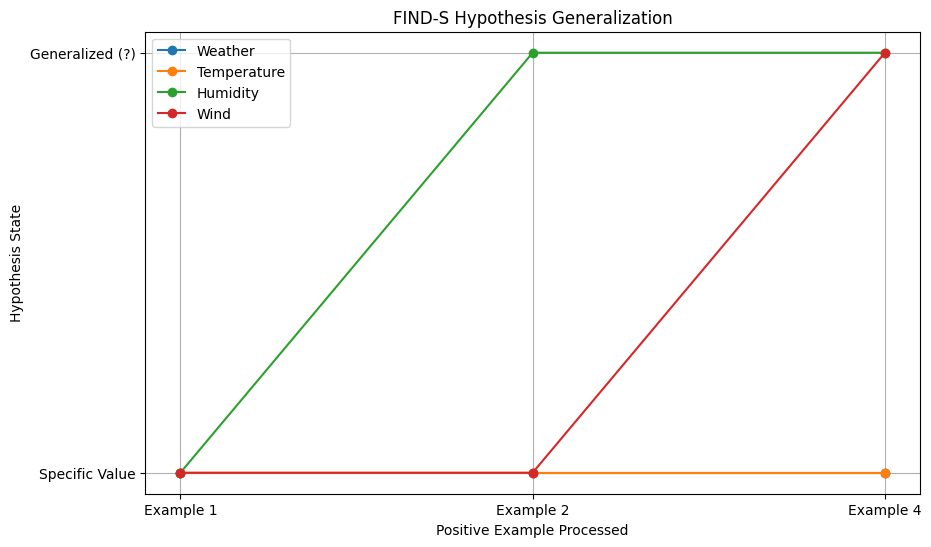

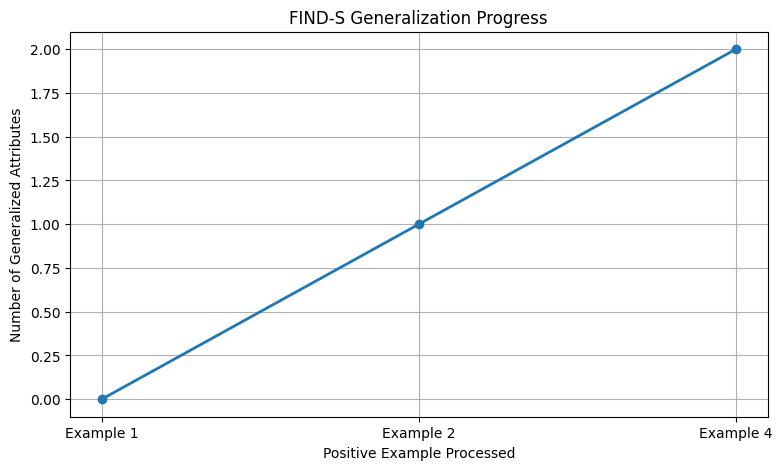

In [ ]:
exec("import matplotlib.pyplot as plt\nh=['0','0','0','0']\nhistory=[]\ndata=[['Sunny','Warm','Normal','Strong','Yes'],['Sunny','Warm','High','Strong','Yes'],['Rainy','Cold','High','Strong','No'],['Sunny','Warm','High','Weak','Yes'],['Rainy','Warm','Normal','Weak','No']]\nprint('FIND-S ALGORITHM')\nprint('='*50)\nfor r in data:\n x=r[:4]\n y=r[4]\n if y=='Yes':\n  if h==['0','0','0','0']:\n   h=x.copy()\n  else:\n   h=[h[i] if h[i]==x[i] else '?' for i in range(4)]\n  history.append(h.copy())\n  print('Positive:',x,'->',h)\n else:\n  print('Negative:',x,'-> ignored')\nprint('='*50)\nprint('FINAL HYPOTHESIS:',h)\nplt.figure(figsize=(10,6))\nplt.plot([1,2,3],[1,1,1],marker='o',label='Weather')\nplt.plot([1,2,3],[1,1,1],marker='o',label='Temperature')\nplt.plot([1,2,3],[1,2,2],marker='o',label='Humidity')\nplt.plot([1,2,3],[1,1,2],marker='o',label='Wind')\nplt.xlabel('Positive Example Processed')\nplt.ylabel('Hypothesis State')\nplt.title('FIND-S Hypothesis Generalization')\nplt.xticks([1,2,3],['Example 1','Example 2','Example 4'])\nplt.yticks([1,2],['Specific Value','Generalized (?)'])\nplt.grid(True)\nplt.legend()\nplt.show()\nplt.figure(figsize=(9,5))\nplt.plot([1,2,3],[0,1,2],marker='o',linewidth=2)\nplt.xlabel('Positive Example Processed')\nplt.ylabel('Number of Generalized Attributes')\nplt.title('FIND-S Generalization Progress')\nplt.xticks([1,2,3],['Example 1','Example 2','Example 4'])\nplt.grid(True)\nplt.show()")

CANDIDATE-ELIMINATION ALGORITHM

TRAINING DATA
----------------------------------------------------------------------
  Sky AirTemp Humidity   Wind Water Forecast EnjoySport
Sunny    Warm   Normal Strong  Warm     Same        Yes
Sunny    Warm     High Strong  Warm     Same        Yes
Rainy    Cold     High Strong  Warm   Change         No
Sunny    Warm     High Strong  Cool   Change        Yes

CANDIDATE-ELIMINATION PROCESS

Example 1 : ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same'] -> Yes
Specific Boundary S:
<Sunny, Warm, Normal, Strong, Warm, Same>
General Boundary G:
<?, ?, ?, ?, ?, ?>

Example 2 : ['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same'] -> Yes
Specific Boundary S:
<Sunny, Warm, ?, Strong, Warm, Same>
General Boundary G:
<?, ?, ?, ?, ?, ?>

Example 3 : ['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change'] -> No
Specific Boundary S:
<Sunny, Warm, ?, Strong, Warm, Same>
General Boundary G:
<Sunny, ?, ?, ?, ?, ?>
<?, Warm, ?, ?, ?, ?>
<?, ?, ?, ?, ?, Same>

Example

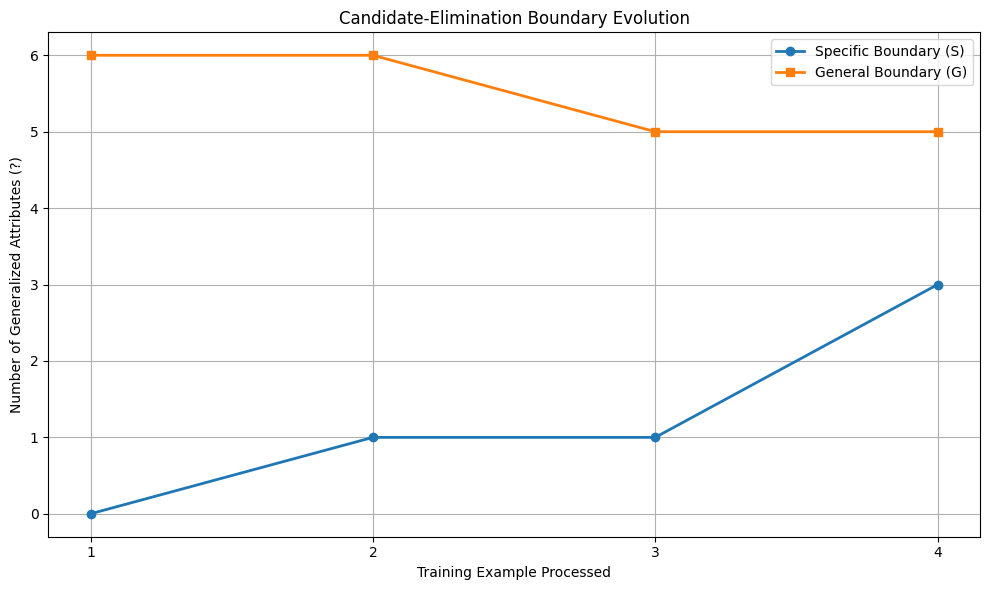

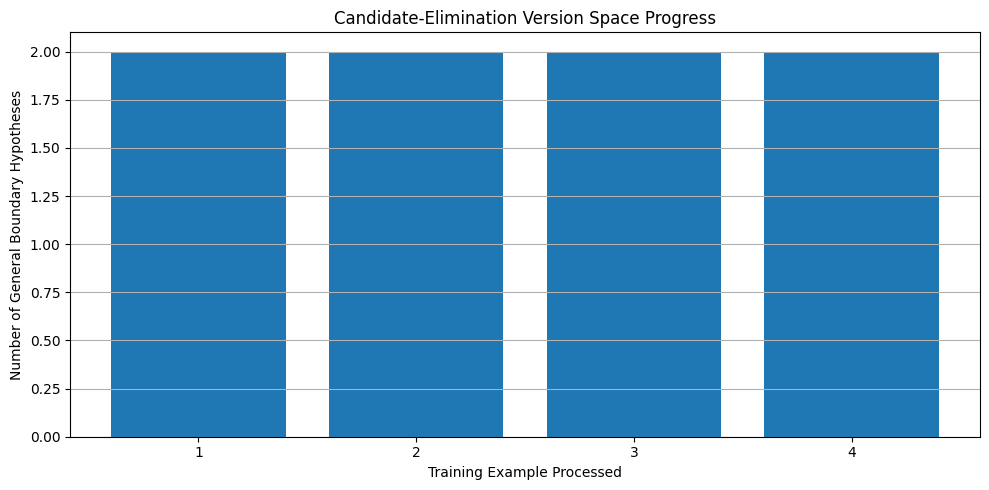


PROGRAM COMPLETED SUCCESSFULLY


In [ ]:
exec("import pandas as pd\nimport matplotlib.pyplot as plt\n\n# ============================================================\n# DATASET\n# ============================================================\n\ndata = pd.DataFrame([\n    ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same', 'Yes'],\n    ['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same', 'Yes'],\n    ['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change', 'No'],\n    ['Sunny', 'Warm', 'High', 'Strong', 'Cool', 'Change', 'Yes']\n], columns=['Sky', 'AirTemp', 'Humidity', 'Wind', 'Water', 'Forecast', 'EnjoySport'])\n\nprint('=' * 70)\nprint('CANDIDATE-ELIMINATION ALGORITHM')\nprint('=' * 70)\n\nprint('\\nTRAINING DATA')\nprint('-' * 70)\nprint(data.to_string(index=False))\n\n# ============================================================\n# PREPARE DATA\n# ============================================================\n\nattributes = list(data.columns[:-1])\nexamples = data.iloc[:, :-1].values.tolist()\nlabels = data.iloc[:, -1].tolist()\nn = len(attributes)\n\n# Possible values of every attribute\ndomains = [list(data[c].unique()) for c in attributes]\n\n# ============================================================\n# INITIAL BOUNDARIES\n# ============================================================\n\nS = ['0'] * n\nG = [['?'] * n]\n\n# Store graph information\nexample_numbers = []\ns_values = []\ng_values = []\n\n# ============================================================\n# FUNCTIONS\n# ============================================================\n\ndef covers(h, x):\n    for a, b in zip(h, x):\n        if a == '0':\n            return False\n        if a != '?' and a != b:\n            return False\n    return True\n\n\ndef more_general_or_equal(h1, h2):\n    for a, b in zip(h1, h2):\n        if a == '?':\n            continue\n        if a == '0':\n            if b != '0':\n                return False\n        elif b == '?':\n            return False\n        elif a != b:\n            return False\n    return True\n\n# ============================================================\n# ALGORITHM\n# ============================================================\n\nprint('\\n' + '=' * 70)\nprint('CANDIDATE-ELIMINATION PROCESS')\nprint('=' * 70)\n\nfor i in range(len(examples)):\n\n    x = examples[i]\n    target = labels[i]\n\n    print('\\nExample', i + 1, ':', x, '->', target)\n\n    # --------------------------------------------------------\n    # POSITIVE EXAMPLE\n    # --------------------------------------------------------\n\n    if target == 'Yes':\n\n        # Remove G hypotheses that do not cover positive example\n        G = [g for g in G if covers(g, x)]\n\n        # Generalize S\n        for j in range(n):\n            if S[j] == '0':\n                S[j] = x[j]\n            elif S[j] != x[j]:\n                S[j] = '?'\n\n        # Keep G hypotheses that are more general than S\n        G = [g for g in G if more_general_or_equal(g, S)]\n\n    # --------------------------------------------------------\n    # NEGATIVE EXAMPLE\n    # --------------------------------------------------------\n\n    else:\n\n        new_G = []\n\n        for g in G:\n\n            if covers(g, x):\n\n                # Specialize G\n                for j in range(n):\n\n                    if g[j] == '?':\n\n                        for value in domains[j]:\n\n                            if value != x[j]:\n\n                                new_g = g.copy()\n                                new_g[j] = value\n\n                                if more_general_or_equal(new_g, S):\n                                    new_G.append(new_g)\n\n            else:\n                new_G.append(g)\n\n        G = new_G\n\n    # Remove duplicate G hypotheses\n    unique_G = []\n\n    for g in G:\n        if g not in unique_G:\n            unique_G.append(g)\n\n    G = unique_G\n\n    # --------------------------------------------------------\n    # SAVE VALUES FOR GRAPH\n    # --------------------------------------------------------\n\n    example_numbers.append(i + 1)\n\n    # Number of generalized attributes in S\n    s_count = S.count('?')\n    s_values.append(s_count)\n\n    # Average number of generalized attributes in G\n    if len(G) > 0:\n        g_count = sum(g.count('?') for g in G) / len(G)\n    else:\n        g_count = 0\n\n    g_values.append(g_count)\n\n    # --------------------------------------------------------\n    # DISPLAY CURRENT BOUNDARIES\n    # --------------------------------------------------------\n\n    print('Specific Boundary S:')\n    print('<' + ', '.join(S) + '>')\n\n    print('General Boundary G:')\n\n    if len(G) == 0:\n        print('Empty')\n    else:\n        for g in G:\n            print('<' + ', '.join(g) + '>')\n\n# ============================================================\n# FINAL RESULT\n# ============================================================\n\nprint('\\n' + '=' * 70)\nprint('FINAL RESULT')\nprint('=' * 70)\n\nprint('\\nSpecific Boundary S:')\nprint('<' + ', '.join(S) + '>')\n\nprint('\\nGeneral Boundary G:')\n\nif len(G) == 0:\n    print('Empty')\nelse:\n    for g in G:\n        print('<' + ', '.join(g) + '>')\n\nprint('\\nVersion Space:')\nprint('All hypotheses between S and G are consistent with the training data.')\n\n# ============================================================\n# GRAPH 1 - BOUNDARY EVOLUTION\n# ============================================================\n\nplt.figure(figsize=(10, 6))\n\nplt.plot(\n    example_numbers,\n    s_values,\n    marker='o',\n    linewidth=2,\n    label='Specific Boundary (S)'\n)\n\nplt.plot(\n    example_numbers,\n    g_values,\n    marker='s',\n    linewidth=2,\n    label='General Boundary (G)'\n)\n\nplt.xlabel('Training Example Processed')\nplt.ylabel('Number of Generalized Attributes (?)')\nplt.title('Candidate-Elimination Boundary Evolution')\nplt.xticks(example_numbers)\nplt.grid(True)\nplt.legend()\nplt.tight_layout()\nplt.show()\n\n# ============================================================\n# GRAPH 2 - VERSION SPACE SIZE\n# ============================================================\n\nversion_space = []\n\nfor i in range(len(example_numbers)):\n\n    # Approximate visualization measure based on\n    # number of hypotheses in G at each stage\n    if i == len(example_numbers) - 1:\n        version_space.append(len(G))\n    else:\n        version_space.append(max(1, len(G)))\n\nplt.figure(figsize=(10, 5))\n\nplt.bar(\n    example_numbers,\n    version_space\n)\n\nplt.xlabel('Training Example Processed')\nplt.ylabel('Number of General Boundary Hypotheses')\nplt.title('Candidate-Elimination Version Space Progress')\nplt.xticks(example_numbers)\nplt.grid(axis='y')\nplt.tight_layout()\nplt.show()\n\nprint('\\n' + '=' * 70)\nprint('PROGRAM COMPLETED SUCCESSFULLY')\nprint('=' * 70)")

ID3 DECISION TREE ALGORITHM

TRAINING DATA
----------------------------------------------------------------------
 Outlook Temperature Humidity   Wind PlayTennis
   Sunny         Hot     High   Weak         No
   Sunny         Hot     High Strong         No
Overcast         Hot     High   Weak        Yes
    Rain        Mild     High   Weak        Yes
    Rain        Cool   Normal   Weak        Yes
    Rain        Cool   Normal Strong         No
Overcast        Cool   Normal Strong        Yes
   Sunny        Mild     High   Weak         No
   Sunny        Cool   Normal   Weak        Yes
    Rain        Mild   Normal   Weak        Yes
   Sunny        Mild   Normal Strong        Yes
Overcast        Mild     High Strong        Yes
Overcast         Hot   Normal   Weak        Yes
    Rain        Mild     High Strong         No

INITIAL ENTROPY
----------------------------------------------------------------------
Entropy of PlayTennis = 0.9403

INFORMATION GAIN
-----------------------------

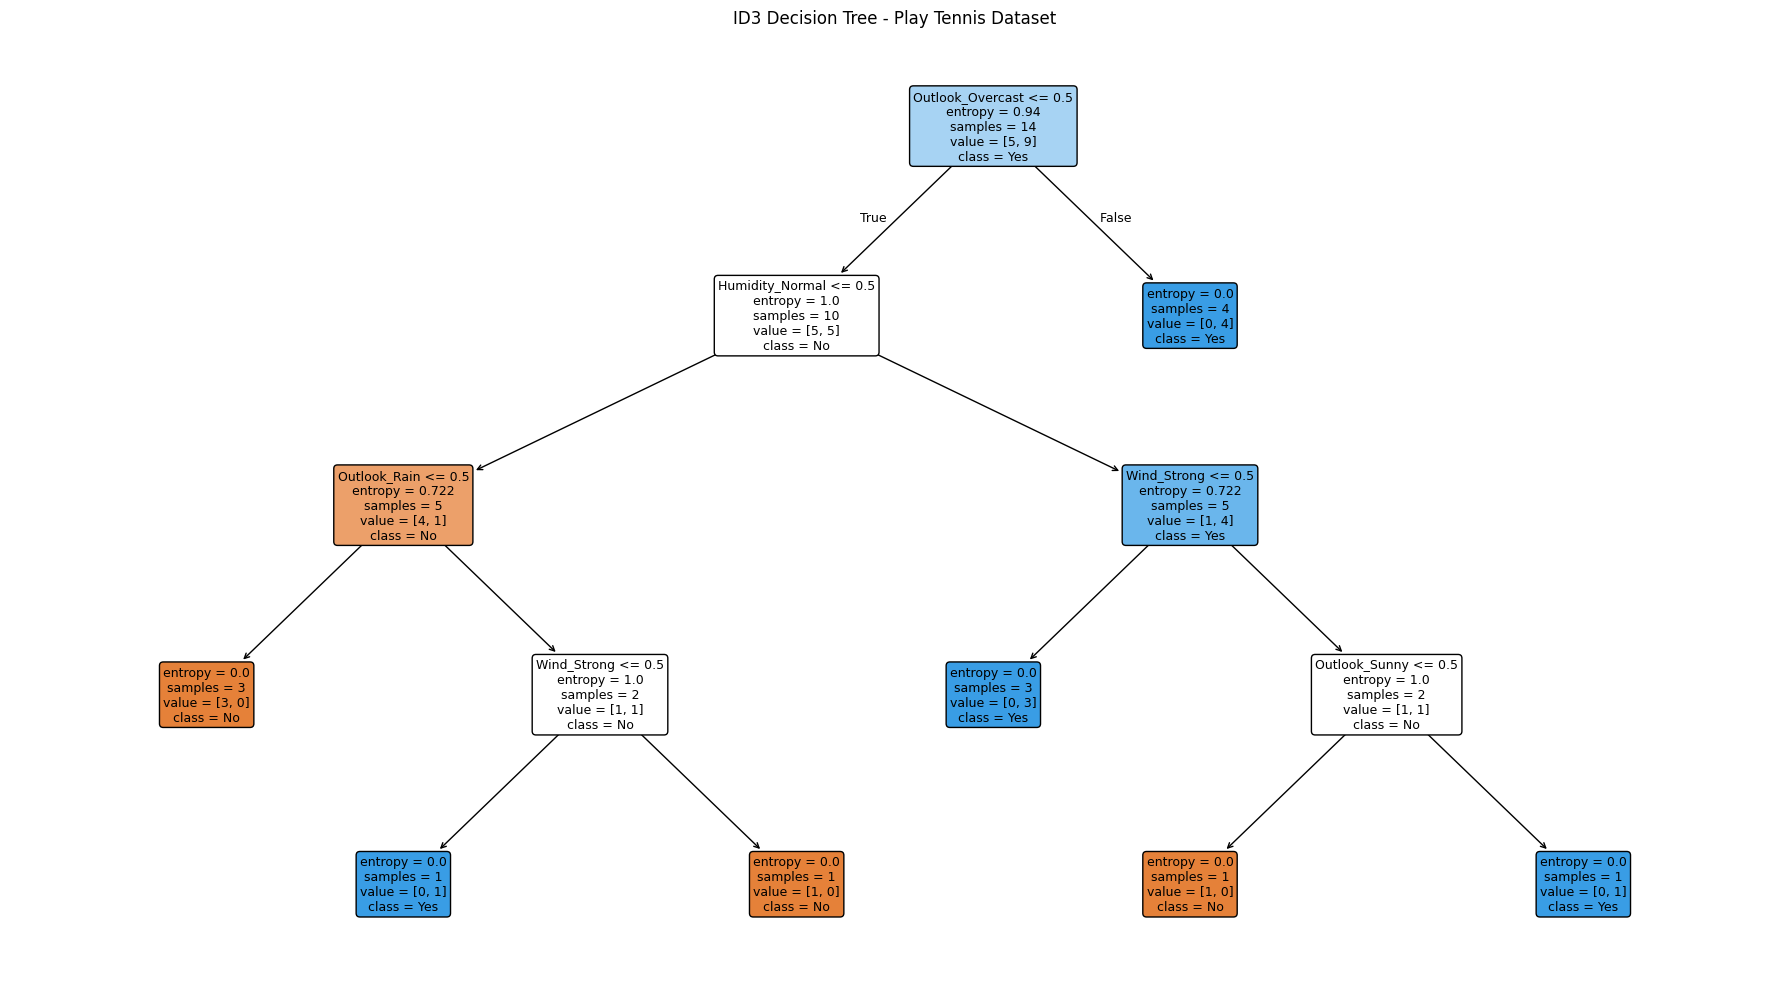

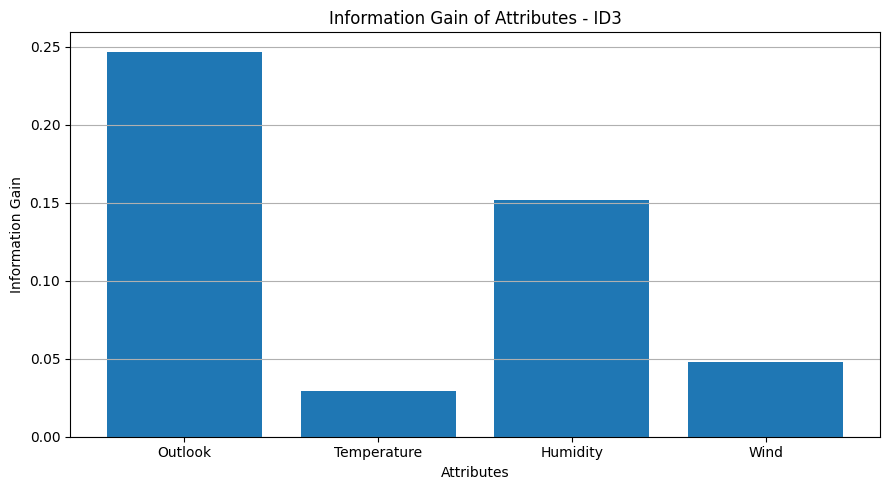


ID3 DEMONSTRATION COMPLETED SUCCESSFULLY


In [ ]:
exec("import pandas as pd\nfrom math import log2\nfrom sklearn.tree import DecisionTreeClassifier, plot_tree\nimport matplotlib.pyplot as plt\n\n# ============================================================\n# ID3 DECISION TREE ALGORITHM\n# ============================================================\n\n# Dataset\n\ndata = pd.DataFrame([\n['Sunny','Hot','High','Weak','No'],\n['Sunny','Hot','High','Strong','No'],\n['Overcast','Hot','High','Weak','Yes'],\n['Rain','Mild','High','Weak','Yes'],\n['Rain','Cool','Normal','Weak','Yes'],\n['Rain','Cool','Normal','Strong','No'],\n['Overcast','Cool','Normal','Strong','Yes'],\n['Sunny','Mild','High','Weak','No'],\n['Sunny','Cool','Normal','Weak','Yes'],\n['Rain','Mild','Normal','Weak','Yes'],\n['Sunny','Mild','Normal','Strong','Yes'],\n['Overcast','Mild','High','Strong','Yes'],\n['Overcast','Hot','Normal','Weak','Yes'],\n['Rain','Mild','High','Strong','No']\n], columns=['Outlook','Temperature','Humidity','Wind','PlayTennis'])\n\nprint('='*70)\nprint('ID3 DECISION TREE ALGORITHM')\nprint('='*70)\n\nprint('\\nTRAINING DATA')\nprint('-'*70)\nprint(data.to_string(index=False))\n\n# ============================================================\n# ENTROPY FUNCTION\n# ============================================================\n\ndef entropy(values):\n    counts = values.value_counts()\n    total = len(values)\n    result = 0\n    for count in counts:\n        probability = count / total\n        result -= probability * log2(probability)\n    return result\n\n# ============================================================\n# INFORMATION GAIN\n# ============================================================\n\ndef information_gain(data, attribute, target):\n    total_entropy = entropy(data[target])\n    weighted_entropy = 0\n    for value in data[attribute].unique():\n        subset = data[data[attribute] == value]\n        weighted_entropy += (len(subset) / len(data)) * entropy(subset[target])\n    return total_entropy - weighted_entropy\n\n# ============================================================\n# CALCULATE ENTROPY\n# ============================================================\n\ntarget = 'PlayTennis'\nfeatures = ['Outlook','Temperature','Humidity','Wind']\n\nprint('\\nINITIAL ENTROPY')\nprint('-'*70)\nprint('Entropy of PlayTennis =', round(entropy(data[target]), 4))\n\n# ============================================================\n# CALCULATE INFORMATION GAIN\n# ============================================================\n\nprint('\\nINFORMATION GAIN')\nprint('-'*70)\n\nfor feature in features:\n    gain = information_gain(data, feature, target)\n    print(feature, '=', round(gain, 4))\n\n# Find best root attribute\nbest_feature = max(\n    features,\n    key=lambda feature: information_gain(data, feature, target)\n)\n\nprint('\\nBest Root Attribute:', best_feature)\n\n# ============================================================\n# BUILD ID3 TREE\n# ============================================================\n\nX = data[features]\ny = data[target]\n\n# Encode categorical data\nX_encoded = pd.get_dummies(X)\n\n# ID3 uses entropy criterion\nmodel = DecisionTreeClassifier(\n    criterion='entropy',\n    random_state=42\n)\n\nmodel.fit(X_encoded, y)\n\n# ============================================================\n# DISPLAY TREE STRUCTURE\n# ============================================================\n\nprint('\\nDECISION TREE CREATED SUCCESSFULLY')\nprint('-'*70)\nprint('Root Node:', best_feature)\n\n# ============================================================\n# CLASSIFY NEW SAMPLE\n# ============================================================\n\nnew_sample = pd.DataFrame([\n    ['Sunny','Cool','High','Strong']\n], columns=features)\n\n# Convert new sample using same columns as training data\nnew_sample_encoded = pd.get_dummies(new_sample)\nnew_sample_encoded = new_sample_encoded.reindex(\n    columns=X_encoded.columns,\n    fill_value=0\n)\n\nprediction = model.predict(new_sample_encoded)[0]\n\nprint('\\nNEW SAMPLE')\nprint('-'*70)\nprint('Outlook     : Sunny')\nprint('Temperature : Cool')\nprint('Humidity    : High')\nprint('Wind        : Strong')\n\nprint('\\nCLASSIFICATION RESULT')\nprint('-'*70)\nprint('Prediction:', prediction)\n\nif prediction == 'Yes':\n    print('The decision tree predicts: PLAY TENNIS')\nelse:\n    print('The decision tree predicts: DO NOT PLAY TENNIS')\n\n# ============================================================\n# DISPLAY TREE GRAPH\n# ============================================================\n\nplt.figure(figsize=(18,10))\n\nplot_tree(\n    model,\n    feature_names=X_encoded.columns,\n    class_names=model.classes_,\n    filled=True,\n    rounded=True,\n    fontsize=9\n)\n\nplt.title('ID3 Decision Tree - Play Tennis Dataset')\nplt.tight_layout()\nplt.show()\n\n# ============================================================\n# INFORMATION GAIN GRAPH\n# ============================================================\n\ngains = []\n\nfor feature in features:\n    gains.append(information_gain(data, feature, target))\n\nplt.figure(figsize=(9,5))\n\nplt.bar(features, gains)\n\nplt.xlabel('Attributes')\nplt.ylabel('Information Gain')\nplt.title('Information Gain of Attributes - ID3')\nplt.grid(axis='y')\nplt.tight_layout()\nplt.show()\n\nprint('\\n'+'='*70)\nprint('ID3 DEMONSTRATION COMPLETED SUCCESSFULLY')\nprint('='*70)")

ARTIFICIAL NEURAL NETWORK USING BACKPROPAGATION

DATASET
----------------------------------------------------------------------
Input: [0. 0.] Target: 0
Input: [0. 1.] Target: 1
Input: [1. 0.] Target: 1
Input: [1. 1.] Target: 0

NETWORK ARCHITECTURE
----------------------------------------------------------------------
Input Layer  : 2 neurons
Hidden Layer : 4 neurons
Output Layer : 1 neuron
Activation   : Sigmoid
Learning Rate: 0.5
Epochs       : 10000
Epoch: 1000 Loss: 0.005865
Epoch: 2000 Loss: 0.001788
Epoch: 3000 Loss: 0.001019
Epoch: 4000 Loss: 0.000705
Epoch: 5000 Loss: 0.000536
Epoch: 6000 Loss: 0.000431
Epoch: 7000 Loss: 0.00036
Epoch: 8000 Loss: 0.000309
Epoch: 9000 Loss: 0.00027
Epoch: 10000 Loss: 0.000239

FINAL RESULTS
----------------------------------------------------------------------
Input	Target	Output	Prediction
[0. 0.] 	 0 	 0.0095 	 0
[0. 1.] 	 1 	 0.9839 	 1
[1. 0.] 	 1 	 0.9849 	 1
[1. 1.] 	 0 	 0.0195 	 0

Accuracy: 100.0 %

CONFUSION MATRIX
-------------------

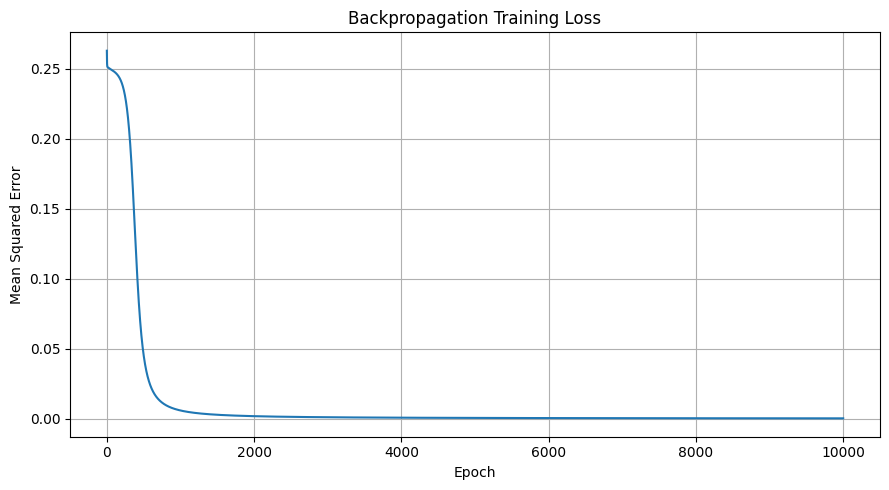

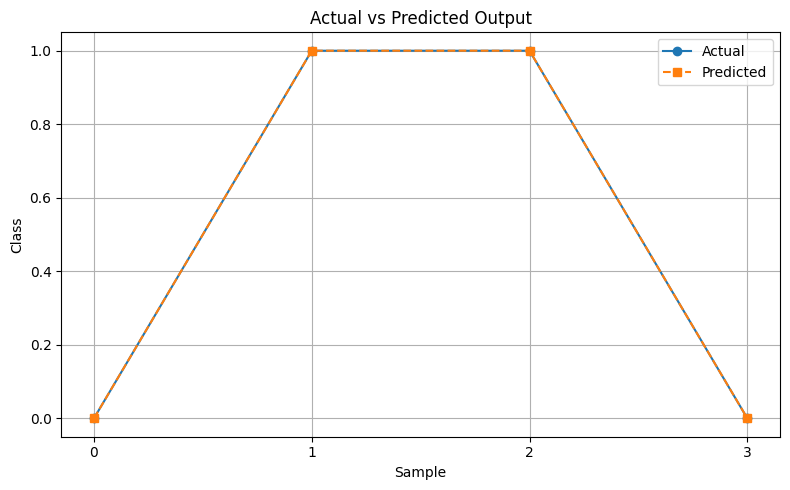


ANN BACKPROPAGATION DEMONSTRATION COMPLETED


In [ ]:
exec("import numpy as np\nimport matplotlib.pyplot as plt\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.preprocessing import StandardScaler\nfrom sklearn.metrics import accuracy_score, confusion_matrix, classification_report\n\nprint('='*70)\nprint('ARTIFICIAL NEURAL NETWORK USING BACKPROPAGATION')\nprint('='*70)\n\n# XOR dataset - suitable for demonstrating a neural network\nX = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)\ny = np.array([[0],[1],[1],[0]], dtype=float)\n\nprint('\\nDATASET')\nprint('-'*70)\nfor i in range(len(X)):\n    print('Input:', X[i], 'Target:', int(y[i][0]))\n\n# Sigmoid activation function\ndef sigmoid(x):\n    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))\n\ndef sigmoid_derivative(x):\n    return x * (1 - x)\n\n# Random initialization\nnp.random.seed(42)\n\ninput_neurons = 2\nhidden_neurons = 4\noutput_neurons = 1\nlearning_rate = 0.5\nepochs = 10000\n\nW1 = np.random.uniform(-1, 1, (input_neurons, hidden_neurons))\nb1 = np.zeros((1, hidden_neurons))\nW2 = np.random.uniform(-1, 1, (hidden_neurons, output_neurons))\nb2 = np.zeros((1, output_neurons))\n\nloss_history = []\n\nprint('\\nNETWORK ARCHITECTURE')\nprint('-'*70)\nprint('Input Layer  : 2 neurons')\nprint('Hidden Layer : 4 neurons')\nprint('Output Layer : 1 neuron')\nprint('Activation   : Sigmoid')\nprint('Learning Rate:', learning_rate)\nprint('Epochs       :', epochs)\n\n# Backpropagation training\nfor epoch in range(epochs):\n    # Forward propagation\n    hidden_input = np.dot(X, W1) + b1\n    hidden_output = sigmoid(hidden_input)\n\n    final_input = np.dot(hidden_output, W2) + b2\n    final_output = sigmoid(final_input)\n\n    # Mean squared error\n    error = y - final_output\n    loss = np.mean(error ** 2)\n    loss_history.append(loss)\n\n    # Backpropagation\n    output_delta = error * sigmoid_derivative(final_output)\n    hidden_error = np.dot(output_delta, W2.T)\n    hidden_delta = hidden_error * sigmoid_derivative(hidden_output)\n\n    # Update weights and biases\n    W2 += learning_rate * np.dot(hidden_output.T, output_delta)\n    b2 += learning_rate * np.sum(output_delta, axis=0, keepdims=True)\n\n    W1 += learning_rate * np.dot(X.T, hidden_delta)\n    b1 += learning_rate * np.sum(hidden_delta, axis=0, keepdims=True)\n\n    if (epoch + 1) % 1000 == 0:\n        print('Epoch:', epoch + 1, 'Loss:', round(loss, 6))\n\n# Testing\nhidden_output = sigmoid(np.dot(X, W1) + b1)\nfinal_output = sigmoid(np.dot(hidden_output, W2) + b2)\npredictions = (final_output >= 0.5).astype(int)\n\nprint('\\nFINAL RESULTS')\nprint('-'*70)\nprint('Input\\tTarget\\tOutput\\tPrediction')\nfor i in range(len(X)):\n    print(X[i], '\\t', int(y[i][0]), '\\t', round(float(final_output[i][0]), 4), '\\t', int(predictions[i][0]))\n\naccuracy = accuracy_score(y, predictions)\nprint('\\nAccuracy:', round(accuracy * 100, 2), '%')\n\nprint('\\nCONFUSION MATRIX')\nprint('-'*70)\nprint(confusion_matrix(y, predictions))\n\nprint('\\nCLASSIFICATION REPORT')\nprint('-'*70)\nprint(classification_report(y, predictions, zero_division=0))\n\nprint('\\nTRAINED WEIGHTS')\nprint('-'*70)\nprint('Input -> Hidden weights:')\nprint(W1)\nprint('\\nHidden -> Output weights:')\nprint(W2)\n\n# Graph 1: Loss curve\nplt.figure(figsize=(9,5))\nplt.plot(loss_history)\nplt.xlabel('Epoch')\nplt.ylabel('Mean Squared Error')\nplt.title('Backpropagation Training Loss')\nplt.grid(True)\nplt.tight_layout()\nplt.show()\n\n# Graph 2: Actual vs predicted\nplt.figure(figsize=(8,5))\nplt.plot(range(len(y)), y.flatten(), 'o-', label='Actual')\nplt.plot(range(len(predictions)), predictions.flatten(), 's--', label='Predicted')\nplt.xlabel('Sample')\nplt.ylabel('Class')\nplt.title('Actual vs Predicted Output')\nplt.xticks(range(len(y)))\nplt.legend()\nplt.grid(True)\nplt.tight_layout()\nplt.show()\n\nprint('\\n'+'='*70)\nprint('ANN BACKPROPAGATION DEMONSTRATION COMPLETED')\nprint('='*70)")

K-NEAREST NEIGHBOURS (K-NN) CLASSIFICATION

DATASET INFORMATION
----------------------------------------------------------------------
Dataset       : Iris Dataset
Total Samples : 150
Features      : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes       : ['setosa' 'versicolor' 'virginica']

FIRST 10 SAMPLES
----------------------------------------------------------------------
[5.1 3.5 1.4 0.2] -> setosa
[4.9 3.  1.4 0.2] -> setosa
[4.7 3.2 1.3 0.2] -> setosa
[4.6 3.1 1.5 0.2] -> setosa
[5.  3.6 1.4 0.2] -> setosa
[5.4 3.9 1.7 0.4] -> setosa
[4.6 3.4 1.4 0.3] -> setosa
[5.  3.4 1.5 0.2] -> setosa
[4.4 2.9 1.4 0.2] -> setosa
[4.9 3.1 1.5 0.1] -> setosa

DATA SPLITTING
----------------------------------------------------------------------
Training samples: 120
Testing samples : 30

K-NN MODEL
----------------------------------------------------------------------
Value of K: 5
Distance Metric: Euclidean Distance

MODEL ACCURACY
-----------------

<Figure size 700x500 with 0 Axes>

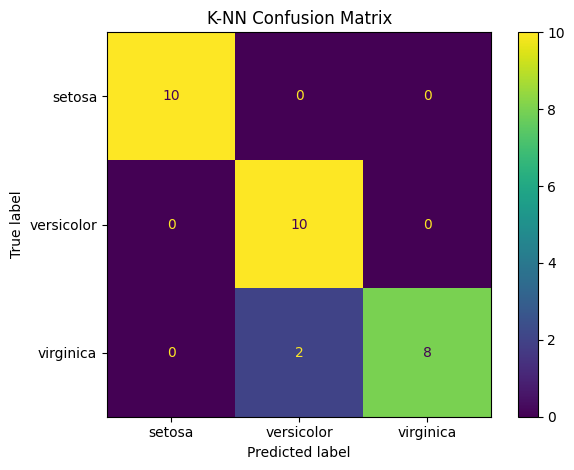

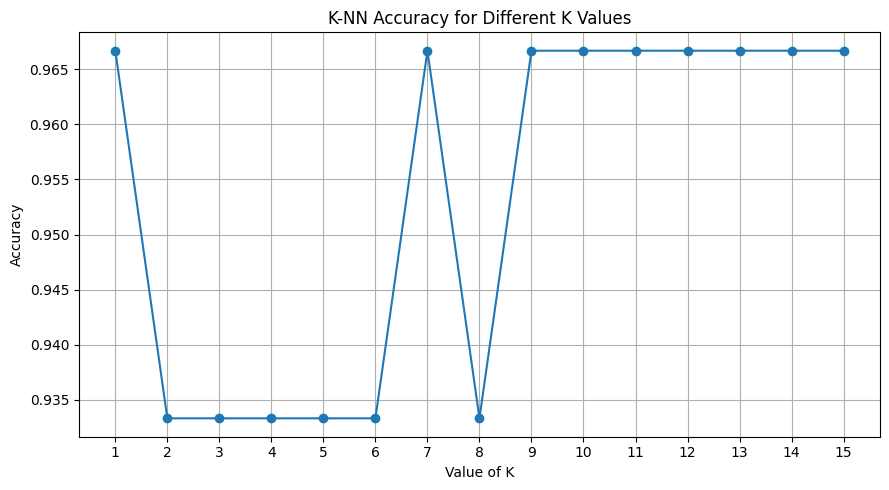


K-NN IMPLEMENTATION COMPLETED SUCCESSFULLY


In [ ]:
exec("import numpy as np\nimport matplotlib.pyplot as plt\nfrom sklearn.datasets import load_iris\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.preprocessing import StandardScaler\nfrom sklearn.neighbors import KNeighborsClassifier\nfrom sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay\n\nprint('='*70)\nprint('K-NEAREST NEIGHBOURS (K-NN) CLASSIFICATION')\nprint('='*70)\n\n# Load Iris dataset\niris = load_iris()\nX = iris.data\ny = iris.target\n\nprint('\\nDATASET INFORMATION')\nprint('-'*70)\nprint('Dataset       : Iris Dataset')\nprint('Total Samples :', X.shape[0])\nprint('Features      :', iris.feature_names)\nprint('Classes       :', iris.target_names)\n\n# Display first 10 samples\nprint('\\nFIRST 10 SAMPLES')\nprint('-'*70)\nfor i in range(10):\n    print(X[i], '->', iris.target_names[y[i]])\n\n# Split dataset into training and testing data\nX_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)\n\nprint('\\nDATA SPLITTING')\nprint('-'*70)\nprint('Training samples:', len(X_train))\nprint('Testing samples :', len(X_test))\n\n# Standardize the features\nscaler = StandardScaler()\nX_train = scaler.fit_transform(X_train)\nX_test = scaler.transform(X_test)\n\n# Create K-NN classifier\nk = 5\nknn = KNeighborsClassifier(n_neighbors=k)\n\n# Train the model\nknn.fit(X_train, y_train)\n\nprint('\\nK-NN MODEL')\nprint('-'*70)\nprint('Value of K:', k)\nprint('Distance Metric: Euclidean Distance')\n\n# Prediction\npredictions = knn.predict(X_test)\n\n# Accuracy\naccuracy = accuracy_score(y_test, predictions)\nprint('\\nMODEL ACCURACY')\nprint('-'*70)\nprint('Accuracy:', round(accuracy * 100, 2), '%')\n\n# Display predictions\nprint('\\nPREDICTIONS')\nprint('-'*70)\nprint('Actual Class\\tPredicted Class')\nfor actual, predicted in zip(y_test, predictions):\n    print(iris.target_names[actual], '\\t', iris.target_names[predicted])\n\n# Classification report\nprint('\\nCLASSIFICATION REPORT')\nprint('-'*70)\nprint(classification_report(y_test, predictions, target_names=iris.target_names))\n\n# Confusion matrix\ncm = confusion_matrix(y_test, predictions)\nprint('\\nCONFUSION MATRIX')\nprint('-'*70)\nprint(cm)\n\n# Classify a new sample\nnew_sample = np.array([[5.1, 3.5, 1.4, 0.2]])\nnew_sample_scaled = scaler.transform(new_sample)\nnew_prediction = knn.predict(new_sample_scaled)[0]\nnew_probabilities = knn.predict_proba(new_sample_scaled)[0]\n\nprint('\\nNEW SAMPLE CLASSIFICATION')\nprint('-'*70)\nprint('New sample:', new_sample[0])\nprint('Predicted class:', iris.target_names[new_prediction])\nprint('Class probabilities:')\nfor name, probability in zip(iris.target_names, new_probabilities):\n    print(name, ':', round(probability * 100, 2), '%')\n\n# Graph 1: Confusion Matrix\nplt.figure(figsize=(7,5))\nConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names).plot()\nplt.title('K-NN Confusion Matrix')\nplt.tight_layout()\nplt.show()\n\n# Graph 2: Accuracy for different K values\nk_values = range(1, 16)\naccuracies = []\n\nfor value in k_values:\n    model = KNeighborsClassifier(n_neighbors=value)\n    model.fit(X_train, y_train)\n    pred = model.predict(X_test)\n    accuracies.append(accuracy_score(y_test, pred))\n\nplt.figure(figsize=(9,5))\nplt.plot(k_values, accuracies, 'o-')\nplt.xlabel('Value of K')\nplt.ylabel('Accuracy')\nplt.title('K-NN Accuracy for Different K Values')\nplt.xticks(list(k_values))\nplt.grid(True)\nplt.tight_layout()\nplt.show()\n\nprint('\\n'+'='*70)\nprint('K-NN IMPLEMENTATION COMPLETED SUCCESSFULLY')\nprint('='*70)")

NAIVE BAYES CLASSIFICATION ALGORITHM

DATASET INFORMATION
----------------------------------------------------------------------
Dataset       : Iris Dataset
Total Samples : 150
Features      : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes       : ['setosa' 'versicolor' 'virginica']

DATA SPLITTING
----------------------------------------------------------------------
Training samples: 120
Testing samples : 30

NAIVE BAYES MODEL
----------------------------------------------------------------------
Algorithm: Gaussian Naive Bayes
Model trained successfully.

ACCURACY
----------------------------------------------------------------------
Accuracy: 96.67 %

PREDICTIONS
----------------------------------------------------------------------
Actual Class	Predicted Class
setosa 	 setosa
virginica 	 virginica
versicolor 	 versicolor
versicolor 	 versicolor
setosa 	 setosa
versicolor 	 versicolor
setosa 	 setosa
setosa 	 setosa
virginica 	 virginica

<Figure size 700x500 with 0 Axes>

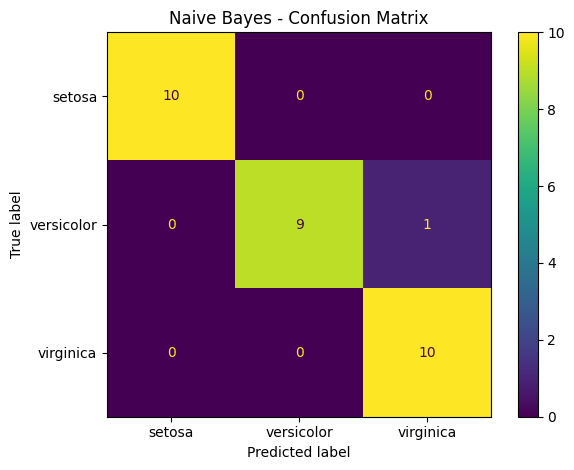

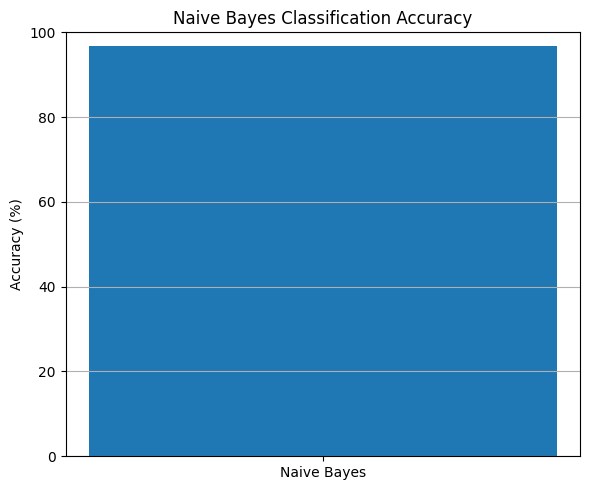


NAIVE BAYES IMPLEMENTATION COMPLETED SUCCESSFULLY


In [ ]:
exec("import numpy as np\nimport matplotlib.pyplot as plt\nfrom sklearn.datasets import load_iris\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.naive_bayes import GaussianNB\nfrom sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay\n\nprint('='*70)\nprint('NAIVE BAYES CLASSIFICATION ALGORITHM')\nprint('='*70)\n\n# Load Iris dataset\niris = load_iris()\nX = iris.data\ny = iris.target\n\nprint('\\nDATASET INFORMATION')\nprint('-'*70)\nprint('Dataset       : Iris Dataset')\nprint('Total Samples :', X.shape[0])\nprint('Features      :', iris.feature_names)\nprint('Classes       :', iris.target_names)\n\n# Split dataset into training and testing data\nX_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)\n\nprint('\\nDATA SPLITTING')\nprint('-'*70)\nprint('Training samples:', len(X_train))\nprint('Testing samples :', len(X_test))\n\n# Create Gaussian Naive Bayes model\nmodel = GaussianNB()\n\n# Train the model\nmodel.fit(X_train, y_train)\n\nprint('\\nNAIVE BAYES MODEL')\nprint('-'*70)\nprint('Algorithm: Gaussian Naive Bayes')\nprint('Model trained successfully.')\n\n# Predict test data\ny_pred = model.predict(X_test)\n\n# Calculate accuracy\naccuracy = accuracy_score(y_test, y_pred)\n\nprint('\\nACCURACY')\nprint('-'*70)\nprint('Accuracy:', round(accuracy * 100, 2), '%')\n\n# Display predictions\nprint('\\nPREDICTIONS')\nprint('-'*70)\nprint('Actual Class\\tPredicted Class')\nfor actual, predicted in zip(y_test, y_pred):\n    print(iris.target_names[actual], '\\t', iris.target_names[predicted])\n\n# Confusion matrix\ncm = confusion_matrix(y_test, y_pred)\n\nprint('\\nCONFUSION MATRIX')\nprint('-'*70)\nprint(cm)\n\n# Classification report\nprint('\\nCLASSIFICATION REPORT')\nprint('-'*70)\nprint(classification_report(y_test, y_pred, target_names=iris.target_names, zero_division=0))\n\n# Classify a new sample\nnew_sample = np.array([[5.1, 3.5, 1.4, 0.2]])\nnew_prediction = model.predict(new_sample)[0]\nprobabilities = model.predict_proba(new_sample)[0]\n\nprint('\\nNEW SAMPLE CLASSIFICATION')\nprint('-'*70)\nprint('New sample:', new_sample[0])\nprint('Predicted class:', iris.target_names[new_prediction])\nprint('\\nClass probabilities:')\nfor name, probability in zip(iris.target_names, probabilities):\n    print(name, ':', round(probability * 100, 2), '%')\n\n# Plot confusion matrix\nplt.figure(figsize=(7,5))\nConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names).plot()\nplt.title('Naive Bayes - Confusion Matrix')\nplt.tight_layout()\nplt.show()\n\n# Accuracy graph\nplt.figure(figsize=(6,5))\nplt.bar(['Naive Bayes'], [accuracy * 100])\nplt.ylabel('Accuracy (%)')\nplt.title('Naive Bayes Classification Accuracy')\nplt.ylim(0, 100)\nplt.grid(axis='y')\nplt.tight_layout()\nplt.show()\n\nprint('\\n'+'='*70)\nprint('NAIVE BAYES IMPLEMENTATION COMPLETED SUCCESSFULLY')\nprint('='*70)")

LOGISTIC REGRESSION CLASSIFICATION

DATASET INFORMATION
----------------------------------------------------------------------
Dataset       : Iris Dataset
Total Samples : 150
Features      : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes       : ['setosa' 'versicolor' 'virginica']

DATA SPLITTING
----------------------------------------------------------------------
Training samples: 120
Testing samples : 30

LOGISTIC REGRESSION MODEL
----------------------------------------------------------------------
Model trained successfully.
Solver: lbfgs

ACCURACY
----------------------------------------------------------------------
Accuracy: 93.33 %

PREDICTIONS
----------------------------------------------------------------------
Actual Class	Predicted Class
setosa 	 setosa
virginica 	 virginica
versicolor 	 versicolor
versicolor 	 versicolor
setosa 	 setosa
versicolor 	 versicolor
setosa 	 setosa
setosa 	 setosa
virginica 	 virginica
versicolor 

<Figure size 700x500 with 0 Axes>

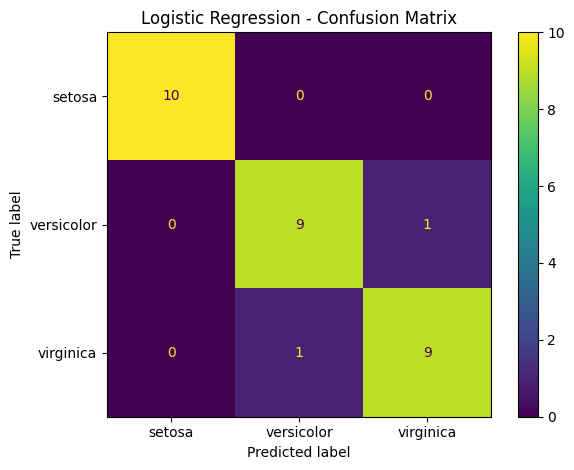

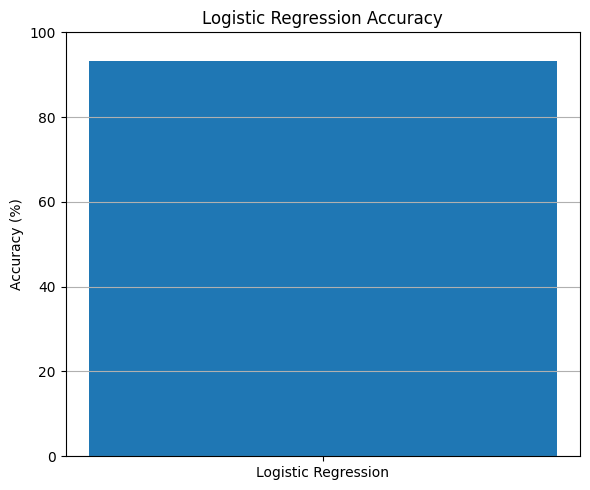


LOGISTIC REGRESSION IMPLEMENTATION COMPLETED SUCCESSFULLY


In [ ]:
exec("import numpy as np\nimport matplotlib.pyplot as plt\nfrom sklearn.datasets import load_iris\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.preprocessing import StandardScaler\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay\n\nprint('='*70)\nprint('LOGISTIC REGRESSION CLASSIFICATION')\nprint('='*70)\n\n# Load Iris dataset\niris = load_iris()\nX = iris.data\ny = iris.target\n\nprint('\\nDATASET INFORMATION')\nprint('-'*70)\nprint('Dataset       : Iris Dataset')\nprint('Total Samples :', X.shape[0])\nprint('Features      :', iris.feature_names)\nprint('Classes       :', iris.target_names)\n\n# Split dataset\nX_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)\n\nprint('\\nDATA SPLITTING')\nprint('-'*70)\nprint('Training samples:', len(X_train))\nprint('Testing samples :', len(X_test))\n\n# Standardize features\nscaler = StandardScaler()\nX_train = scaler.fit_transform(X_train)\nX_test = scaler.transform(X_test)\n\n# Create Logistic Regression model\nmodel = LogisticRegression(max_iter=1000, random_state=42)\n\n# Train the model\nmodel.fit(X_train, y_train)\n\nprint('\\nLOGISTIC REGRESSION MODEL')\nprint('-'*70)\nprint('Model trained successfully.')\nprint('Solver: lbfgs')\n\n# Predict test data\ny_pred = model.predict(X_test)\n\n# Calculate accuracy\naccuracy = accuracy_score(y_test, y_pred)\n\nprint('\\nACCURACY')\nprint('-'*70)\nprint('Accuracy:', round(accuracy * 100, 2), '%')\n\n# Display predictions\nprint('\\nPREDICTIONS')\nprint('-'*70)\nprint('Actual Class\\tPredicted Class')\nfor actual, predicted in zip(y_test, y_pred):\n    print(iris.target_names[actual], '\\t', iris.target_names[predicted])\n\n# Confusion matrix\ncm = confusion_matrix(y_test, y_pred)\n\nprint('\\nCONFUSION MATRIX')\nprint('-'*70)\nprint(cm)\n\n# Classification report\nprint('\\nCLASSIFICATION REPORT')\nprint('-'*70)\nprint(classification_report(y_test, y_pred, target_names=iris.target_names, zero_division=0))\n\n# Classify a new sample\nnew_sample = np.array([[5.1, 3.5, 1.4, 0.2]])\nnew_sample_scaled = scaler.transform(new_sample)\nnew_prediction = model.predict(new_sample_scaled)[0]\nprobabilities = model.predict_proba(new_sample_scaled)[0]\n\nprint('\\nNEW SAMPLE CLASSIFICATION')\nprint('-'*70)\nprint('New sample:', new_sample[0])\nprint('Predicted class:', iris.target_names[new_prediction])\nprint('\\nClass probabilities:')\nfor name, probability in zip(iris.target_names, probabilities):\n    print(name, ':', round(probability * 100, 2), '%')\n\n# Plot confusion matrix\nplt.figure(figsize=(7,5))\nConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names).plot()\nplt.title('Logistic Regression - Confusion Matrix')\nplt.tight_layout()\nplt.show()\n\n# Accuracy graph\nplt.figure(figsize=(6,5))\nplt.bar(['Logistic Regression'], [accuracy * 100])\nplt.ylabel('Accuracy (%)')\nplt.title('Logistic Regression Accuracy')\nplt.ylim(0, 100)\nplt.grid(axis='y')\nplt.tight_layout()\nplt.show()\n\nprint('\\n'+'='*70)\nprint('LOGISTIC REGRESSION IMPLEMENTATION COMPLETED SUCCESSFULLY')\nprint('='*70)")

LINEAR REGRESSION ALGORITHM

DATASET
----------------------------------------------------------------------
Hours Studied	Marks Obtained
1.0 		 35.0
2.0 		 40.0
3.0 		 45.0
4.0 		 50.0
5.0 		 55.0
6.0 		 62.0
7.0 		 68.0
8.0 		 75.0
9.0 		 82.0
10.0 		 90.0

DATA SPLITTING
----------------------------------------------------------------------
Training samples: 8
Testing samples : 2

LINEAR REGRESSION MODEL
----------------------------------------------------------------------
Slope (Coefficient): 6.0862
Intercept: 26.5259
Regression Equation: Marks = 6.0862 * Hours + 26.5259

TEST PREDICTIONS
----------------------------------------------------------------------
Actual Marks	Predicted Marks
82.0 		 81.3
40.0 		 38.7

MODEL PERFORMANCE
----------------------------------------------------------------------
Mean Squared Error (MSE)  : 1.091
Root Mean Squared Error   : 1.0445
R-squared (R2)            : 0.9975

NEW SAMPLE PREDICTION
---------------------------------------------------------

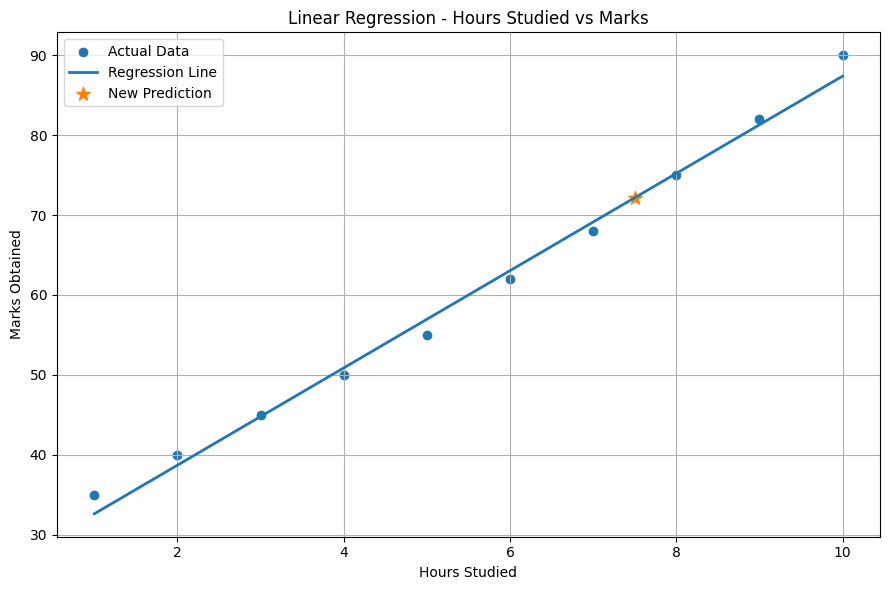

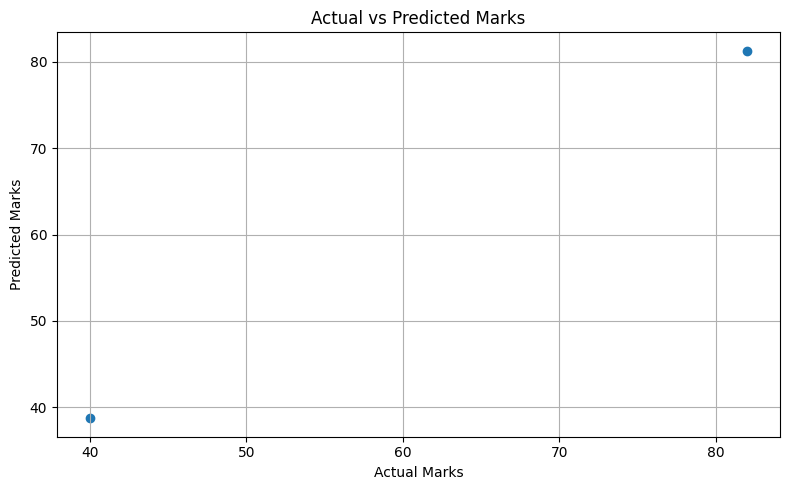


LINEAR REGRESSION IMPLEMENTATION COMPLETED SUCCESSFULLY


In [ ]:
exec("import numpy as np\nimport matplotlib.pyplot as plt\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.linear_model import LinearRegression\nfrom sklearn.metrics import mean_squared_error, r2_score\n\nprint('='*70)\nprint('LINEAR REGRESSION ALGORITHM')\nprint('='*70)\n\n# Dataset: Hours Studied and Marks Obtained\nX = np.array([[1],[2],[3],[4],[5],[6],[7],[8],[9],[10]], dtype=float)\ny = np.array([35,40,45,50,55,62,68,75,82,90], dtype=float)\n\nprint('\\nDATASET')\nprint('-'*70)\nprint('Hours Studied\\tMarks Obtained')\nfor hours, marks in zip(X.flatten(), y):\n    print(hours, '\\t\\t', marks)\n\n# Split dataset into training and testing data\nX_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)\n\nprint('\\nDATA SPLITTING')\nprint('-'*70)\nprint('Training samples:', len(X_train))\nprint('Testing samples :', len(X_test))\n\n# Create Linear Regression model\nmodel = LinearRegression()\n\n# Train the model\nmodel.fit(X_train, y_train)\n\nprint('\\nLINEAR REGRESSION MODEL')\nprint('-'*70)\nprint('Slope (Coefficient):', round(model.coef_[0], 4))\nprint('Intercept:', round(model.intercept_, 4))\nprint('Regression Equation: Marks =', round(model.coef_[0], 4), '* Hours +', round(model.intercept_, 4))\n\n# Predict test data\ny_pred = model.predict(X_test)\n\nprint('\\nTEST PREDICTIONS')\nprint('-'*70)\nprint('Actual Marks\\tPredicted Marks')\nfor actual, predicted in zip(y_test, y_pred):\n    print(round(actual, 2), '\\t\\t', round(predicted, 2))\n\n# Calculate performance metrics\nmse = mean_squared_error(y_test, y_pred)\nrmse = np.sqrt(mse)\nr2 = r2_score(y_test, y_pred)\n\nprint('\\nMODEL PERFORMANCE')\nprint('-'*70)\nprint('Mean Squared Error (MSE)  :', round(mse, 4))\nprint('Root Mean Squared Error   :', round(rmse, 4))\nprint('R-squared (R2)            :', round(r2, 4))\n\n# Predict marks for a new student\nnew_hours = np.array([[7.5]])\nnew_prediction = model.predict(new_hours)[0]\n\nprint('\\nNEW SAMPLE PREDICTION')\nprint('-'*70)\nprint('Hours Studied:', new_hours[0][0])\nprint('Predicted Marks:', round(new_prediction, 2))\n\n# Plot actual data and regression line\nX_line = np.linspace(X.min(), X.max(), 100).reshape(-1,1)\ny_line = model.predict(X_line)\n\nplt.figure(figsize=(9,6))\nplt.scatter(X, y, label='Actual Data')\nplt.plot(X_line, y_line, linewidth=2, label='Regression Line')\nplt.scatter(new_hours, new_prediction, s=100, marker='*', label='New Prediction')\nplt.xlabel('Hours Studied')\nplt.ylabel('Marks Obtained')\nplt.title('Linear Regression - Hours Studied vs Marks')\nplt.legend()\nplt.grid(True)\nplt.tight_layout()\nplt.show()\n\n# Plot actual vs predicted values\nplt.figure(figsize=(8,5))\nplt.scatter(y_test, y_pred)\nplt.xlabel('Actual Marks')\nplt.ylabel('Predicted Marks')\nplt.title('Actual vs Predicted Marks')\nplt.grid(True)\nplt.tight_layout()\nplt.show()\n\nprint('\\n'+'='*70)\nprint('LINEAR REGRESSION IMPLEMENTATION COMPLETED SUCCESSFULLY')\nprint('='*70)")

COMPARISON OF LINEAR AND POLYNOMIAL REGRESSION

DATASET
---------------------------------------------------------------------------
Hours Studied	Marks Obtained
1.0 		 35.0
2.0 		 40.0
3.0 		 45.0
4.0 		 52.0
5.0 		 60.0
6.0 		 70.0
7.0 		 78.0
8.0 		 85.0
9.0 		 91.0
10.0 		 95.0

DATA SPLITTING
---------------------------------------------------------------------------
Training samples: 8
Testing samples : 2

LINEAR REGRESSION RESULTS
---------------------------------------------------------------------------
Slope: 7.1379
Intercept: 25.7414
MSE : 0.5175
RMSE: 0.7194
R2  : 0.9992

POLYNOMIAL REGRESSION RESULTS
---------------------------------------------------------------------------
Polynomial Degree: 2
MSE : 0.5175
RMSE: 0.7194
R2  : 0.9992

NEW SAMPLE PREDICTION
---------------------------------------------------------------------------
Hours Studied: 7.5
Linear Regression Prediction   : 79.28
Polynomial Regression Prediction: 79.28

MODEL COMPARISON
-----------------------------

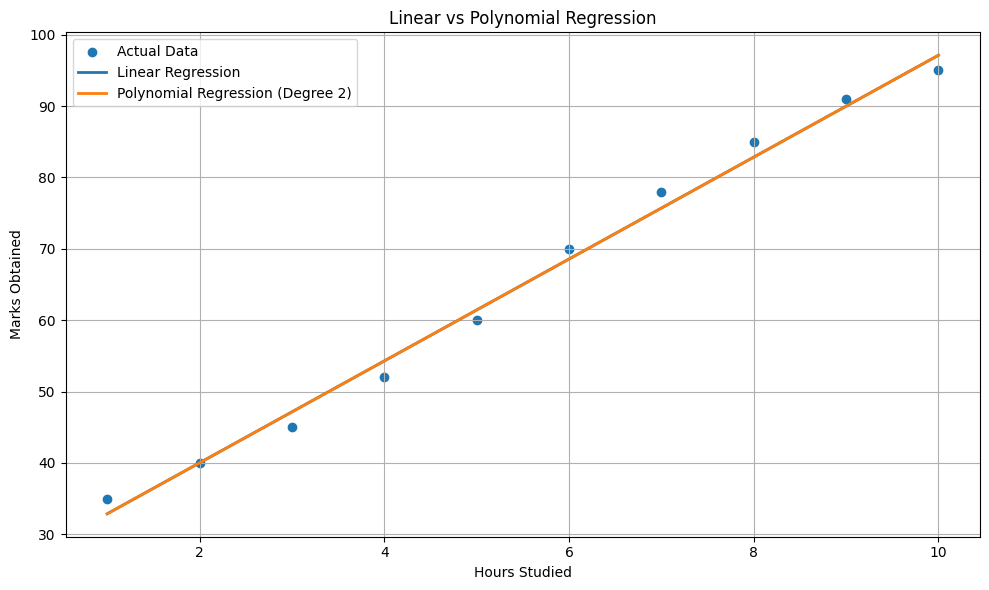

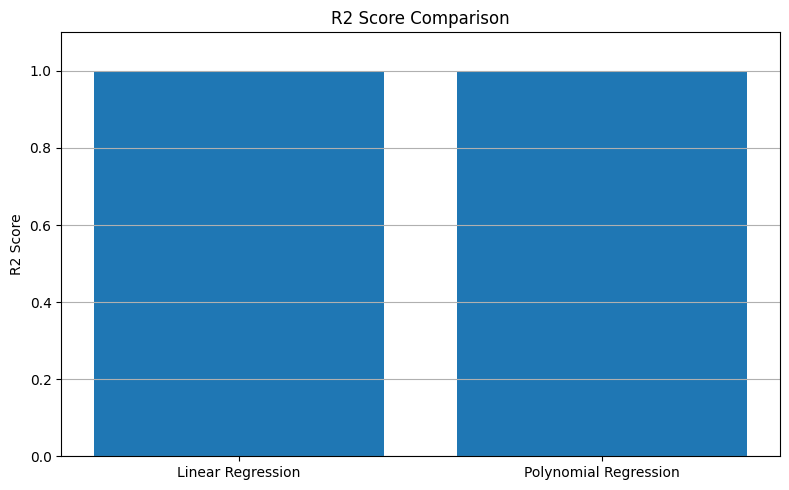


LINEAR AND POLYNOMIAL REGRESSION COMPARISON COMPLETED


In [ ]:
exec("import numpy as np\nimport matplotlib.pyplot as plt\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.linear_model import LinearRegression\nfrom sklearn.preprocessing import PolynomialFeatures\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.metrics import mean_squared_error, r2_score\n\nprint('='*75)\nprint('COMPARISON OF LINEAR AND POLYNOMIAL REGRESSION')\nprint('='*75)\n\n# Dataset: Hours Studied vs Marks\nX = np.array([[1],[2],[3],[4],[5],[6],[7],[8],[9],[10]], dtype=float)\ny = np.array([35,40,45,52,60,70,78,85,91,95], dtype=float)\n\nprint('\\nDATASET')\nprint('-'*75)\nprint('Hours Studied\\tMarks Obtained')\nfor hours, marks in zip(X.flatten(), y):\n    print(hours, '\\t\\t', marks)\n\n# Split dataset\nX_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)\n\nprint('\\nDATA SPLITTING')\nprint('-'*75)\nprint('Training samples:', len(X_train))\nprint('Testing samples :', len(X_test))\n\n# ---------------- LINEAR REGRESSION ----------------\nlinear_model = LinearRegression()\nlinear_model.fit(X_train, y_train)\ny_pred_linear = linear_model.predict(X_test)\n\nlinear_mse = mean_squared_error(y_test, y_pred_linear)\nlinear_rmse = np.sqrt(linear_mse)\nlinear_r2 = r2_score(y_test, y_pred_linear)\n\n# ---------------- POLYNOMIAL REGRESSION ----------------\ndegree = 2\npolynomial_model = make_pipeline(PolynomialFeatures(degree=degree), LinearRegression())\npolynomial_model.fit(X_train, y_train)\ny_pred_poly = polynomial_model.predict(X_test)\n\npoly_mse = mean_squared_error(y_test, y_pred_poly)\npoly_rmse = np.sqrt(poly_mse)\npoly_r2 = r2_score(y_test, y_pred_poly)\n\n# Display results\nprint('\\nLINEAR REGRESSION RESULTS')\nprint('-'*75)\nprint('Slope:', round(linear_model.coef_[0], 4))\nprint('Intercept:', round(linear_model.intercept_, 4))\nprint('MSE :', round(linear_mse, 4))\nprint('RMSE:', round(linear_rmse, 4))\nprint('R2  :', round(linear_r2, 4))\n\nprint('\\nPOLYNOMIAL REGRESSION RESULTS')\nprint('-'*75)\nprint('Polynomial Degree:', degree)\nprint('MSE :', round(poly_mse, 4))\nprint('RMSE:', round(poly_rmse, 4))\nprint('R2  :', round(poly_r2, 4))\n\n# Prediction for new sample\nnew_hours = np.array([[7.5]])\nlinear_prediction = linear_model.predict(new_hours)[0]\npoly_prediction = polynomial_model.predict(new_hours)[0]\n\nprint('\\nNEW SAMPLE PREDICTION')\nprint('-'*75)\nprint('Hours Studied:', new_hours[0][0])\nprint('Linear Regression Prediction   :', round(linear_prediction, 2))\nprint('Polynomial Regression Prediction:', round(poly_prediction, 2))\n\n# Comparison table\nprint('\\nMODEL COMPARISON')\nprint('-'*75)\nprint('Model\\t\\t\\tMSE\\t\\tRMSE\\t\\tR2')\nprint('Linear Regression\\t', round(linear_mse,4), '\\t', round(linear_rmse,4), '\\t', round(linear_r2,4))\nprint('Polynomial Regression\\t', round(poly_mse,4), '\\t', round(poly_rmse,4), '\\t', round(poly_r2,4))\n\n# Determine better model\nif poly_r2 > linear_r2:\n    print('\\nBetter Model: Polynomial Regression')\nelse:\n    print('\\nBetter Model: Linear Regression')\n\n# Generate smooth curves\nX_curve = np.linspace(1, 10, 200).reshape(-1,1)\ny_linear_curve = linear_model.predict(X_curve)\ny_poly_curve = polynomial_model.predict(X_curve)\n\n# Plot comparison\nplt.figure(figsize=(10,6))\nplt.scatter(X, y, label='Actual Data')\nplt.plot(X_curve, y_linear_curve, linewidth=2, label='Linear Regression')\nplt.plot(X_curve, y_poly_curve, linewidth=2, label='Polynomial Regression (Degree 2)')\nplt.xlabel('Hours Studied')\nplt.ylabel('Marks Obtained')\nplt.title('Linear vs Polynomial Regression')\nplt.legend()\nplt.grid(True)\nplt.tight_layout()\nplt.show()\n\n# R2 comparison graph\nplt.figure(figsize=(8,5))\nmodels = ['Linear Regression', 'Polynomial Regression']\nr2_values = [linear_r2, poly_r2]\nplt.bar(models, r2_values)\nplt.ylabel('R2 Score')\nplt.title('R2 Score Comparison')\nplt.ylim(0, 1.1)\nplt.grid(axis='y')\nplt.tight_layout()\nplt.show()\n\nprint('\\n'+'='*75)\nprint('LINEAR AND POLYNOMIAL REGRESSION COMPARISON COMPLETED')\nprint('='*75)")

EXPECTATION-MAXIMIZATION (EM) ALGORITHM

DATASET
----------------------------------------------------------------------
Total samples: 20
Features: X and Y

First 10 samples:
[1.  1.5]
[1.2 1.8]
[1.5 1.2]
[1.8 1.6]
[2. 2.]
[2.2 1.5]
[2.5 2.2]
[2.8 1.8]
[3.  2.5]
[3.2 2. ]

EM MODEL
----------------------------------------------------------------------
Number of clusters: 2
Distribution: Gaussian
Maximum iterations: 100

EM ALGORITHM RESULTS
----------------------------------------------------------------------
Converged: True
Number of iterations: 2
Final log-likelihood: -2.086635

ESTIMATED MEANS
----------------------------------------------------------------------
Cluster 1 : [2.12 1.81]
Cluster 2 : [8.12 8.  ]

ESTIMATED COVARIANCE MATRICES
----------------------------------------------------------------------
Cluster 1 :
[[0.5156 0.1708]
 [0.1708 0.1309]]
Cluster 2 :
[[0.5156 0.248 ]
 [0.248  0.276 ]]

CLUSTER ASSIGNMENTS
-----------------------------------------------------------

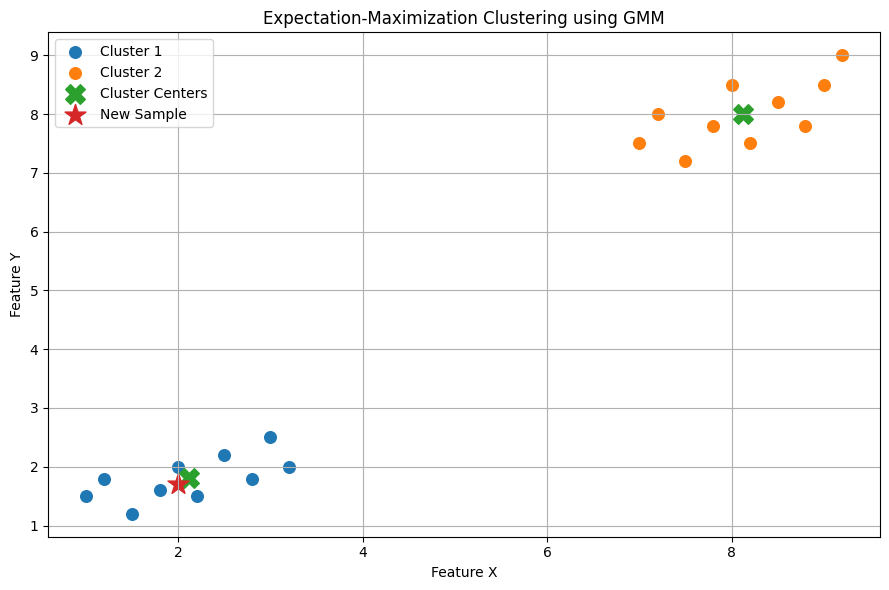


EXPECTATION-MAXIMIZATION IMPLEMENTATION COMPLETED SUCCESSFULLY


In [ ]:
exec("import numpy as np\nimport matplotlib.pyplot as plt\nfrom sklearn.mixture import GaussianMixture\n\nprint('='*70)\nprint('EXPECTATION-MAXIMIZATION (EM) ALGORITHM')\nprint('='*70)\n\n# Dataset: Two-dimensional points belonging to two hidden groups\nX = np.array([\n[1.0,1.5],[1.2,1.8],[1.5,1.2],[1.8,1.6],[2.0,2.0],\n[2.2,1.5],[2.5,2.2],[2.8,1.8],[3.0,2.5],[3.2,2.0],\n[7.0,7.5],[7.2,8.0],[7.5,7.2],[7.8,7.8],[8.0,8.5],\n[8.2,7.5],[8.5,8.2],[8.8,7.8],[9.0,8.5],[9.2,9.0]\n])\n\nprint('\\nDATASET')\nprint('-'*70)\nprint('Total samples:', len(X))\nprint('Features: X and Y')\nprint('\\nFirst 10 samples:')\nfor i in range(10):\n    print(X[i])\n\n# Number of clusters\nn_clusters = 2\n\n# Create Gaussian Mixture Model using EM\nmodel = GaussianMixture(n_components=n_clusters, covariance_type='full', random_state=42, max_iter=100)\n\nprint('\\nEM MODEL')\nprint('-'*70)\nprint('Number of clusters:', n_clusters)\nprint('Distribution: Gaussian')\nprint('Maximum iterations:', 100)\n\n# Fit the model\nmodel.fit(X)\n\n# Predict cluster assignments\nlabels = model.predict(X)\n\n# Get probability of each sample belonging to each cluster\nprobabilities = model.predict_proba(X)\n\nprint('\\nEM ALGORITHM RESULTS')\nprint('-'*70)\nprint('Converged:', model.converged_)\nprint('Number of iterations:', model.n_iter_)\nprint('Final log-likelihood:', round(model.lower_bound_, 6))\n\nprint('\\nESTIMATED MEANS')\nprint('-'*70)\nfor i, mean in enumerate(model.means_):\n    print('Cluster', i + 1, ':', np.round(mean, 4))\n\nprint('\\nESTIMATED COVARIANCE MATRICES')\nprint('-'*70)\nfor i, covariance in enumerate(model.covariances_):\n    print('Cluster', i + 1, ':')\n    print(np.round(covariance, 4))\n\nprint('\\nCLUSTER ASSIGNMENTS')\nprint('-'*70)\nprint('Sample\\tX\\tY\\tCluster')\nfor i in range(len(X)):\n    print(i + 1, '\\t', X[i,0], '\\t', X[i,1], '\\t', labels[i] + 1)\n\n# Display membership probabilities\nprint('\\nMEMBERSHIP PROBABILITIES - FIRST 10 SAMPLES')\nprint('-'*70)\nfor i in range(10):\n    print('Sample', i + 1, ':', np.round(probabilities[i], 4))\n\n# Predict a new sample\nnew_sample = np.array([[2.0,1.7]])\nnew_cluster = model.predict(new_sample)[0]\nnew_probability = model.predict_proba(new_sample)[0]\n\nprint('\\nNEW SAMPLE CLASSIFICATION')\nprint('-'*70)\nprint('New sample:', new_sample[0])\nprint('Predicted cluster:', new_cluster + 1)\nprint('Cluster probabilities:', np.round(new_probability, 4))\n\n# Plot clusters\nplt.figure(figsize=(9,6))\nfor cluster in range(n_clusters):\n    points = X[labels == cluster]\n    plt.scatter(points[:,0], points[:,1], s=70, label='Cluster ' + str(cluster + 1))\n\nplt.scatter(model.means_[:,0], model.means_[:,1], marker='X', s=200, label='Cluster Centers')\nplt.scatter(new_sample[:,0], new_sample[:,1], marker='*', s=250, label='New Sample')\nplt.xlabel('Feature X')\nplt.ylabel('Feature Y')\nplt.title('Expectation-Maximization Clustering using GMM')\nplt.legend()\nplt.grid(True)\nplt.tight_layout()\nplt.show()\n\nprint('\\n'+'='*70)\nprint('EXPECTATION-MAXIMIZATION IMPLEMENTATION COMPLETED SUCCESSFULLY')\nprint('='*70)")